# UNESCO World Heritage Sites: Exploratory Analysis

Audience: Recently retired couples planning a year of travel.

This notebook loads the UNESCO Excel file, checks the data, and creates three charts.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

file_path = '/content/download.xlsx'
df = pd.read_excel(file_path)

print('Rows:', len(df))
print('Columns:', len(df.columns))
print(df.columns.tolist())
display(df.head())

/usr/local/lib/python3.13/dist-packages/openpyxl/styles/stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Rows: 1273
Columns: 49
['unique_number', 'id_no', 'rev_bis', 'name_en', 'name_fr', 'name_es', 'name_ru', 'name_ar', 'name_zh', 'short_description_en', 'short_description_fr', 'short_description_es', 'short_description_ru', 'short_description_ar', 'short_description_zh', 'justification_en', 'justification_fr', 'date_inscribed', 'secondary_dates', 'danger', 'date_end', 'danger_list', 'longitude', 'latitude', 'area_hectares', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'N7', 'N8', 'N9', 'N10', 'criteria_txt', 'category', 'category_short', 'states_name_en', 'states_name_fr', 'states_name_es', 'states_name_ru', 'states_name_ar', 'states_name_zh', 'region_en', 'region_fr', 'iso_code', 'udnp_code', 'transboundary']


,unique_number,id_no,rev_bis,name_en,name_fr,name_es,name_ru,name_ar,name_zh,short_description_en,...,states_name_fr,states_name_es,states_name_ru,states_name_ar,states_name_zh,region_en,region_fr,iso_code,udnp_code,transboundary
0,230,208,Rev,Cultural Landscape and Archaeological Remains ...,Paysage culturel et vestiges archéologiques de...,Paisaje cultural y vestigios arqueológicos del...,Культурный ландшафт и археологические находки ...,المنظر الثقافي والبقايا الأثرية في وادي باميان,巴米扬山谷的文化景观和考古遗迹,<p>The cultural landscape and archaeological r...,...,Afghanistan,Afganistán,Афганистан,أفغانستان,阿富汗,Asia and the Pacific,Asie et Pacifique,af,afg,0
1,234,211,Rev,Minaret and Archaeological Remains of Jam,Minaret et vestiges archéologiques de Djam,Minarete y vestigios arqueológicos de Jam,Минарет и археологические объекты в Джеме,مئذنة جام وبقاياها الاثرية,查姆回教寺院尖塔和考古遗址,"<p>The 65m-tall Minaret of Jam is a graceful, ...",...,Afghanistan,Afganistán,Афганистан,أفغانستان,阿富汗,Asia and the Pacific,Asie et Pacifique,af,afg,0
2,1590,569,Bis,Historic Centres of Berat and Gjirokastra,Centres historiques de Berat et de Gjirokastra,Ciudad Museo de Gjirokastra,Исторические центры Берата и Джирокастры,المركزان التاريخيان لبيرات وجيروكاسترا,NaN,<p>Berat and Gjirokastra are inscribed as rare...,...,Albanie,Albania,Албания,ألبانيا,阿尔巴尼亚,Europe and North America,Europe et Amérique du Nord,al,alb,0
3,1563,570,ter,Butrint,Butrint,Butrinto,Древний город Бутринт,بوترنت,布特林特,"<p>Inhabited since prehistoric times, Butrint ...",...,Albanie,Albania,Албания,ألبانيا,阿尔巴尼亚,Europe and North America,Europe et Amérique du Nord,al,alb,0
4,111,102,NaN,Al Qal'a of Beni Hammad,La Kalâa des Béni Hammad,Kalâa de los Béni-Hammad,Крепость Аль-Кала в древнем городе Бени-Хаммад,قلعة بني حمّاد,贝尼•哈玛德的卡拉城,<p>In a mountainous site of extraordinary beau...,...,Algérie,Argelia,Алжир,الجزائر,阿尔及利亚,Arab States,États arabes,dz,dza,0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 1. Check and understand the data

In [2]:
# Look at column types and missing values
df.info()
display(df.isna().sum().sort_values(ascending=False).head(15))

# Inspect the variables used below
print('Site categories:')
display(df['category'].value_counts(dropna=False))
print('Inscription years:')
print(df['date_inscribed'].describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1273 entries, 0 to 1272
Data columns (total 49 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   unique_number         1273 non-null   int64  
 1   id_no                 1273 non-null   int64  
 2   rev_bis               253 non-null    object 
 3   name_en               1273 non-null   object 
 4   name_fr               1273 non-null   object 
 5   name_es               1267 non-null   object 
 6   name_ru               1150 non-null   object 
 7   name_ar               1162 non-null   object 
 8   name_zh               1104 non-null   object 
 9   short_description_en  1272 non-null   object 
 10  short_description_fr  1272 non-null   object 
 11  short_description_es  1245 non-null   object 
 12  short_description_ru  1156 non-null   object 
 13  short_description_ar  1164 non-null   object 
 14  short_description_zh  1101 non-null   object 
 15  justification_en     

,0
date_end,1227
secondary_dates,1175
danger_list,1173
rev_bis,1020
justification_fr,951
justification_en,945
short_description_zh,172
name_zh,169
name_ru,123
short_description_ru,117


Site categories:


,count
category,
Cultural,991
Natural,240
Mixed,42


Inscription years:
count    1273.000000
mean     2000.926944
std        13.796881
min      1978.000000
25%      1989.000000
50%      2000.000000
75%      2012.000000
max      2026.000000
Name: date_inscribed, dtype: float64


## 2. Chart 1 — Countries with the most listed sites

Some sites are shared by multiple countries. The code splits the country field and counts a shared site once for each country listed. This means country counts can add up to more than the number of site records.

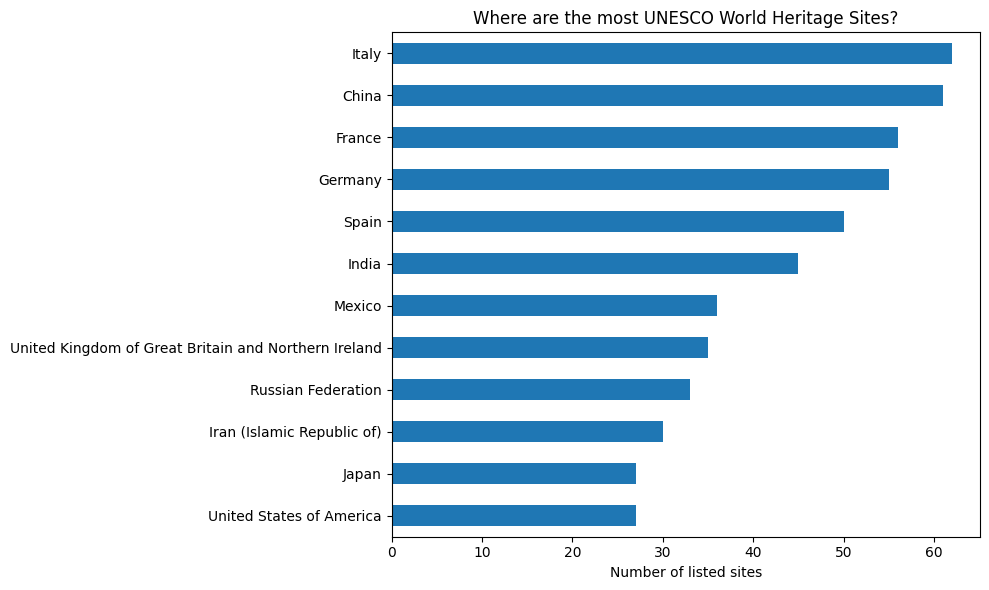

,site_count
country,
Italy,62
China,61
France,56
Germany,55
Spain,50
India,45
Mexico,36
United Kingdom of Great Britain and Northern Ireland,35
Russian Federation,33


In [3]:
country_counts = (
    df.dropna(subset=['states_name_en'])
      .assign(country=lambda x: x['states_name_en'].astype(str).str.split(','))
      .explode('country')
)
country_counts['country'] = country_counts['country'].str.strip()
top_countries = country_counts['country'].value_counts().head(12).sort_values()

ax = top_countries.plot(kind='barh', figsize=(10, 6))
ax.set_title('Where are the most UNESCO World Heritage Sites?')
ax.set_xlabel('Number of listed sites')
ax.set_ylabel('')
plt.tight_layout()
plt.savefig('unesco_chart1_top_countries.png', dpi=200, bbox_inches='tight')
plt.show()

display(top_countries.sort_values(ascending=False).rename('site_count').to_frame())

## 3. Chart 2 — Cultural, natural and mixed sites

This shows the composition of the full list by UNESCO's site category.

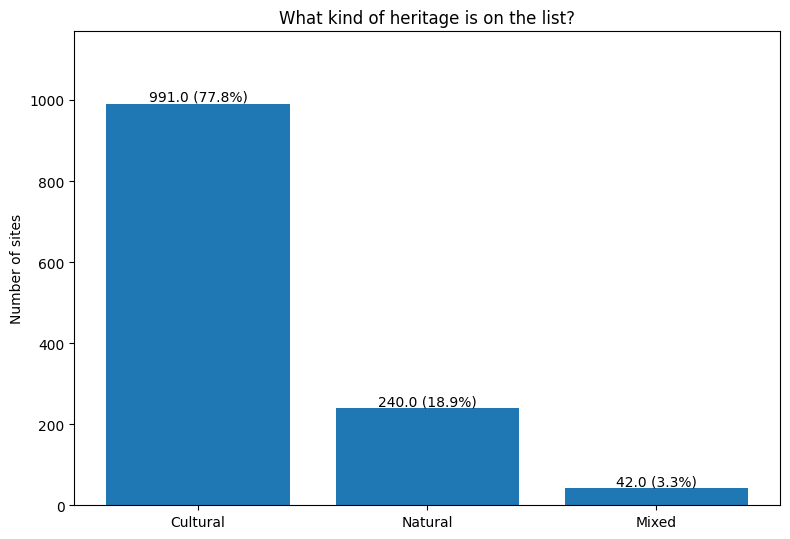

,site_count
category,
Cultural,991.0
Natural,240.0
Mixed,42.0


In [4]:
category_counts = df['category'].fillna('Unknown').value_counts()
category_counts = category_counts.reindex(['Cultural', 'Natural', 'Mixed', 'Unknown']).dropna()

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(category_counts.index, category_counts.values)
ax.set_title('What kind of heritage is on the list?')
ax.set_ylabel('Number of sites')
ax.set_xlabel('')
for bar, value in zip(bars, category_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f'{value:,} ({value/len(df):.1%})', ha='center', va='bottom')
ax.set_ylim(0, max(category_counts.values) * 1.18)
plt.tight_layout()
plt.savefig('unesco_chart2_site_types.png', dpi=200, bbox_inches='tight')
plt.show()

display(category_counts.rename('site_count').to_frame())

## 4. Chart 3 — Sites inscribed by decade

The current dataset includes 2026, which is an incomplete year. We exclude 2026 from the decade chart so the latest partial year does not distort the comparison.

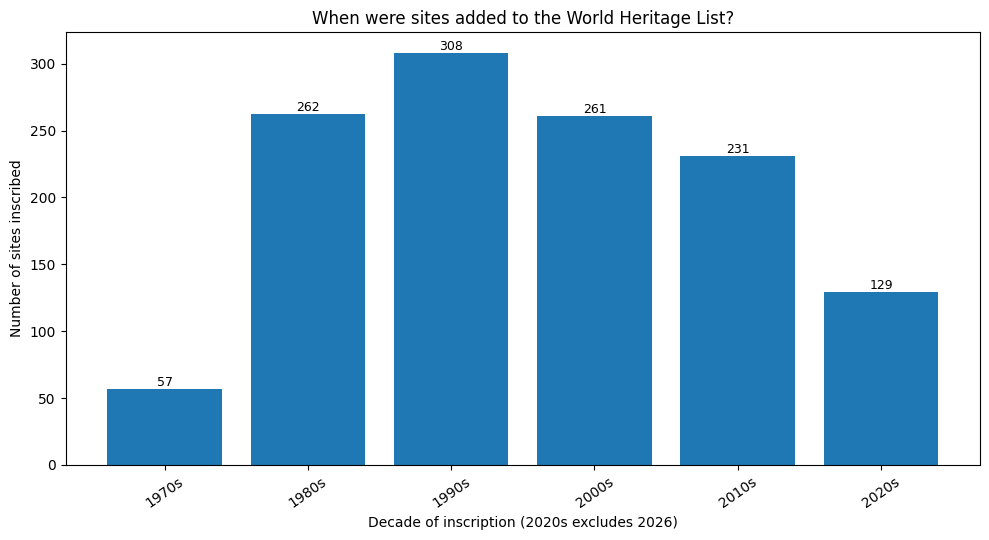

,site_count
date_inscribed,
1970,57
1980,262
1990,308
2000,261
2010,231
2020,129


In [5]:
years = pd.to_numeric(df['date_inscribed'], errors='coerce').dropna().astype(int)
years = years[years < 2026]
decade_counts = ((years // 10) * 10).value_counts().sort_index()
labels = [f'{decade}s' for decade in decade_counts.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.bar(labels, decade_counts.values)
ax.set_title('When were sites added to the World Heritage List?')
ax.set_ylabel('Number of sites inscribed')
ax.set_xlabel('Decade of inscription (2020s excludes 2026)')
ax.tick_params(axis='x', rotation=35)
for bar, value in zip(bars, decade_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), str(value),
            ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.savefig('unesco_chart3_inscription_by_decade.png', dpi=200, bbox_inches='tight')
plt.show()

display(decade_counts.rename('site_count').to_frame())

## 5. Save the charts

The previous cells save three PNG files in the notebook's working directory. In Google Colab, run this cell to download each image.

In [6]:
from google.colab import files
files.download('unesco_chart1_top_countries.png')
files.download('unesco_chart2_site_types.png')
files.download('unesco_chart3_inscription_by_decade.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>